# Train the Confidence Head

This notebook trains the confidence head on a built cache and saves it as a checkpoint. It is for the team members who run the training. [`cache-tutorial.ipynb`](cache-tutorial.ipynb) explains the arrays of the cache, and this notebook uses its terms without explaining them again. The eval team scores the head with its own runner. [`eval-template.ipynb`](eval-template.ipynb) shows how to load a checkpoint from this notebook and predict with it.

The same training runs headless as a batch job: `examples/train_head.py`, with [`guides/training-on-carc.md`](../guides/training-on-carc.md) for CARC. The notebook and the job both call `confhead.train`, so they train the same way and write the same run folder.

### What Is Trained

Depth Anything V2 (DA2) gives every pixel a depth. The confidence head learns where that depth is wrong. For every cell of the cache grid, it outputs `p_error`: the probability that the DA2 depth in the cell is off by more than `tau` = 10%. The error is the AbsRel, |predicted - z| / z, against the lidar depth z.

DA2 is frozen and does not run here: the cache holds its outputs, computed once. The head is the only network that trains. It has 4 convolution layers and about 95,000 weights (section 4).

| | Per camera image |
|---|---|
| input `x` | 68 channels per cell: 64 DA2 decoder features, the DA2 depth, the temporal spread, the radar residual, the radar validity |
| output | 1 logit per cell; `p_error` = sigmoid(logit) |
| `target` | 1 where the AbsRel of the cell is above `tau`, else 0 |
| `mask` | 1 where a lidar point lands in the cell; only these cells count in the loss |

The head learns from scattered cells but predicts every cell, so at inference it needs no lidar. Its inputs come from the camera and the radar, which a deployed car has. One input depends on lidar: the build used the lidar fit to give the keyframe its metric scale when it computed the temporal spread (`temporal.align = "lidar"` in the cache settings).

### How It Trains

| Part | Choice |
|---|---|
| loss | binary cross-entropy over the labeled cells, with the positive cells weighted by negatives / positives |
| optimizer | AdamW, learning rate 1e-3, weight decay 1e-4, cosine decay to 0 over all steps |
| batches | 8 images per batch, 8 epochs |
| checkpoint | the epoch with the lowest loss on dev |

The loss, the optimizer, and the batches come from the Run 1 plan ([`Docs/Wiki/CS566 Confidence Head Training Run 1.md`](../../Docs/Wiki/CS566%20Confidence%20Head%20Training%20Run%201.md)). That plan chooses the checkpoint by its AUSE on dev. This notebook chooses it by the dev loss instead, because the eval team owns AUSE and the other scores. The inputs follow the cache, which departs from the Run 1 plan in several ways ([`Docs/Wiki/CS566 Implementation Deviations and Open Questions.md`](../../Docs/Wiki/CS566%20Implementation%20Deviations%20and%20Open%20Questions.md)). For example, `x` holds the temporal spread, which Run 1 left for Run 2.

The splits follow the dataset strategy ([`Docs/Wiki/CS566 Dataset Strategy.md`](../../Docs/Wiki/CS566%20Dataset%20Strategy.md)). Each split holds whole scenes, because the images of one scene are correlated:

| Split | Scenes | Use |
|---|---|---|
| train | the official train scenes that are not in dev | fit the head |
| dev | 10% of the official train scenes, drawn per condition and weather | choose the checkpoint |
| val | the official val scenes | scored by the eval team, and unused here |

> **Note.** The outputs saved in this notebook come from the v1.0-mini cache at the 132 x 74 grid: 6 train scenes and 2 dev scenes. They show that the code runs end to end, but say little about how well the head works.

## Setup

This section imports the packages and finds the confhead folder. `confhead.train` holds the training: its settings (`TrainConfig`), the split into train and dev, and the training run (`Training`). `confhead.head` holds the head and its loss, and `save_head` and `load_head`, which write and read a checkpoint. The eval runner loads a checkpoint with the same `load_head`. The training reports its progress through `logging`, which the code below prints in the notebook.

In [1]:
import logging
import os
import sys
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

from confhead import Cache, ConfidenceDataset, HeadInputs, TrainConfig, Training, load_config, load_head
from confhead.plot import draw_map
from confhead.train import POSITIVE_RATE_GATE

logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

# The confhead folder: the nearest parent that holds configs/ and pyproject.toml.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir() and (p / "pyproject.toml").is_file())


def table(headers, rows):
    """Rows as a markdown table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return Markdown("\n".join(lines))

## 1. Settings

**Settings to change:** every setting of a run is in the code below. `cfg` is a `TrainConfig`: the same settings that the batch job reads from a TOML file such as [`configs/train-trainval.toml`](../configs/train-trainval.toml). Each name is the section and the key there: `cfg.train.epochs` is `epochs` under `[train]`. The training defaults come from the Run 1 plan, and the split defaults from the dataset strategy. A run writes its settings and its checkpoints to its run folder, and section 9 lists the files.

| Setting | Default | Effect |
|---|---|---|
| `CACHE_ROOT` | `None` | The cache to train on. `None` takes the first cache that exists: your trainval cache on CARC, then the mini caches under `outputs/`. |
| `DATAROOT` | `None` | Where the nuScenes images are, for the demo of section 8. `None`: the folder the cache was built from. |
| `RUNS` | `None` | The folder of all runs. `None`: `/scratch1/$USER/confhead-runs` on CARC, `outputs/runs` elsewhere. |
| `DEMO_KEYS` | `None` | The images of the demo in section 8. `None`: one dev image per condition and weather, at most 3. |
| `cfg.output.name` | `""` | The run folder. Empty names it after the cache and the time. To continue a run that stopped, set it to the name of that folder. |
| `cfg.inputs` | `HeadInputs()` | The channel groups of `x`, `tau`, and the radar settings. Change it for an ablation. |
| `cfg.head.widths` | `[64, 64, 32]` | The channels of the three 3x3 convolutions |
| `cfg.train.epochs`, `cfg.train.batch_size` | 8, 8 | Passes over train, and images per step |
| `cfg.train.lr`, `cfg.train.weight_decay` | 1e-3, 1e-4 | AdamW |
| `cfg.train.samples_per_epoch` | 0 | Train images per epoch, drawn at random. 0: all of them. Section 5 says when to lower it. |
| `cfg.train.dev_fraction` | 0.1 | The share of the official train scenes that go to dev |
| `cfg.train.dev_limit` | 3000 | Dev images for the dev loss after each epoch, a fixed random subset. 0: all of them. |
| `cfg.train.stats_sample` | 256 | Train images for the input statistics and the class weight |
| `cfg.train.seed` | 0 | The seed of the splits, the samples, the initial weights, and the batch order |
| `cfg.run.device` | `"auto"` | `cuda` if there is one, then `mps`, then `cpu` |
| `cfg.run.num_workers` | -1 | Loader processes. -1: one less than the CPUs of the session, at most 8. |

In [2]:
CACHE_ROOT = None
DATAROOT = None
RUNS = None
DEMO_KEYS = None

cfg = TrainConfig()
cfg.output.name = ""
cfg.inputs = HeadInputs()
cfg.head.widths = [64, 64, 32]
cfg.train.epochs = 8
cfg.train.batch_size = 8
cfg.train.lr = 1e-3
cfg.train.weight_decay = 1e-4
cfg.train.samples_per_epoch = 0
cfg.train.dev_fraction = 0.1
cfg.train.dev_limit = 3000
cfg.train.stats_sample = 256
cfg.train.seed = 0
cfg.run.device = "auto"
cfg.run.num_workers = -1

In [3]:
if CACHE_ROOT is None:
    candidates = [load_config(PROJECT / "configs/nuscenes-trainval.toml").output.root,
                  PROJECT / "outputs/cache/nuscenes-mini-g2", PROJECT / "outputs/cache/nuscenes-mini"]
    CACHE_ROOT = next((c for c in candidates if (Path(c) / "index.json").is_file()), None)
    if CACHE_ROOT is None:
        raise FileNotFoundError("no cache found; set CACHE_ROOT, or build one with examples/build_cache.py")
if RUNS is None:
    scratch = Path("/scratch1") / os.environ.get("USER", "")
    RUNS = scratch / "confhead-runs" if scratch.is_dir() else PROJECT / "outputs/runs"
cfg.data.cache, cfg.output.runs = str(CACHE_ROOT), str(RUNS)

cache = Cache(CACHE_ROOT, DATAROOT)
training = Training(cfg, cache)
device = training.device

print(f"cache    {cache.root}: {len(cache)} entries, fingerprint {cache.header['fingerprint']}")
print(f"run      {training.dir}")
print(f"device   {device}" + (f" ({torch.cuda.get_device_name()})" if device.type == "cuda" else "")
      + f", {training.num_workers} loader processes")

cache    /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/cache/nuscenes-mini-g2: 2424 entries, fingerprint e43e53bcb50cb85f
run      /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/runs/nuscenes-mini-g2-20261028-1354
device   mps, 8 loader processes


## 2. The Splits

`Training` takes the images of the official train split, as `ConfidenceDataset(cache, cfg.inputs, tag="train")` does in section 8 of the tutorial. It draws dev from the official train scenes with `dev_scenes`, which groups the scenes by condition and weather and takes `cfg.train.dev_fraction` of each group, at least one scene from a group of 2 or more. So dev holds night and rain scenes whenever the official train split has two or more scenes of that condition and weather. The other scenes are train.

`cfg.train.dev_limit` keeps the dev loss after each epoch quick: the training computes it on a fixed random subset of the dev images. Every epoch uses the same subset, so the losses of two epochs compare directly.

In [4]:
display(table(["split", "scenes", "images", "images used", "night scenes", "rain scenes"], [
    (s["split"], s["scenes"], s["images"], s["used"], s["night_scenes"], s["rain_scenes"]) for s in training.splits()
]))
print(f"dev scenes: {', '.join(training.dev_scenes)}")

| split | scenes | images | images used | night scenes | rain scenes |
|---|---|---|---|---|---|
| train | 6 | 1458 | 1458 | 2 | 1 |
| dev | 2 | 480 | 480 | 1 | 0 |

dev scenes: scene-0796, scene-1100


The night and rain columns count scenes, not images. Images of one scene share their light, their weather, and most of their content, so scenes are the unit to count. Night and rain scenes in dev let the choice of checkpoint see those conditions too.

## 3. Input Statistics and the Class Weight

The channels of `x` have different scales: the features are raw decoder activations, the depth is the disparity over its image mean, and the radar validity is 0 or 1. `training.input_stats()` measures the mean and std of each channel over a sample of train images, and `ConfidenceHead` standardizes each channel with them, so each channel reaches the first convolution with mean 0 and std 1. Its buffers hold the statistics, so every checkpoint carries them.

The same pass counts the labels. `positive_rate` is the share of labeled cells with an AbsRel above `tau`. With fewer positive cells than negative ones, an unweighted loss favors predicting 0 everywhere. `pos_weight` = (1 - positive_rate) / positive_rate, the class weight, gives the two classes the same total weight in the loss. The Run 1 plan also sets a gate on the labels. A positive rate below 0.05 or above 0.70 means that the depth needs a scale per camera before training.

In [5]:
t0 = time.perf_counter()
stats = training.input_stats()
names = training.channels

feat = [i for i, n in enumerate(names) if n.startswith("feature_")]
rows = [(n, f"{stats.mean[i]:.3f}", f"{stats.std[i]:.3f}") for i, n in enumerate(names) if i not in feat]
if feat:
    rows.insert(0, (f"feature_0 to feature_{len(feat) - 1}", f"{stats.mean[feat].min():.2f} to {stats.mean[feat].max():.2f}",
                    f"{stats.std[feat].min():.2f} to {stats.std[feat].max():.2f}"))
display(table(["channel", "mean", "std"], rows))
print(f"{stats.images} train images in {time.perf_counter() - t0:.1f} s; {stats.labeled_fraction:.1%} of cells labeled")
low, high = POSITIVE_RATE_GATE
print(f"positive_rate {stats.positive_rate:.1%} (AbsRel > {cfg.inputs.labels.tau}); "
      f"gate {low:.0%} to {high:.0%}: {'inside' if stats.in_gate else 'OUTSIDE, see the Run 1 plan'}")
print(f"pos_weight {stats.pos_weight:.3f}")

| channel | mean | std |
|---|---|---|
| feature_0 to feature_63 | -17.60 to 45.84 | 0.86 to 40.43 |
| depth | 1.000 | 0.886 |
| temporal_relstd | 0.052 | 0.121 |
| radar_residual | 0.013 | 0.089 |
| radar_valid | 0.034 | 0.182 |

256 train images in 3.2 s; 25.7% of cells labeled
positive_rate 37.2% (AbsRel > 0.1); gate 5% to 70%: inside
pos_weight 1.686


## 4. The Head

`training.new_head()` builds `ConfidenceHead`, the network of the Run 1 plan, with the statistics of section 3. The head standardizes `x` with them, applies three 3x3 convolutions with a ReLU after each, and ends with a 1x1 convolution to one logit per cell. The output has the size of the grid, so each logit lines up with one label.

Three 3x3 convolutions see a window of 7 x 7 cells around each cell, and the code below converts that window to pixels. The window is small, but the decoder features can carry context from the whole image, because the DA2 encoder is a vision transformer. `cfg.head.widths` changes the number and the width of the 3x3 layers.

In [6]:
head = training.new_head()
print(head)

gw, gh = cache.entry(training.dataset.rows[0]).meta["grid_size"]
image_w = cache.entry(training.dataset.rows[0]).meta["image"]["width"]
window = 1 + 2 * len(cfg.head.widths)
print(f"{sum(p.numel() for p in head.parameters()):,} weights; input {len(names)} x {gh} x {gw}, output 1 x {gh} x {gw}")
print(f"each logit sees {window} x {window} cells, about {window * image_w / gw:.0f} px of a {image_w} px wide image")

ConfidenceHead(
  (net): Sequential(
    (0): Conv2d(68, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
  )
)
94,657 weights; input 68 x 74 x 132, output 1 x 74 x 132
each logit sees 7 x 7 cells, about 85 px of a 1600 px wide image


## 5. Loading Speed

Each step of an epoch reads one `.npz` per image from disk, and computes the labels and the radar channels on the CPU. On the trainval cache at the default grid, an image is about 5.4 MB, so one epoch over the train images reads about 800 GB. `training.speed()` measures the loading and the training step apart, and estimates the time of one epoch from the slower of the two. Its loading rate includes the start of the loader processes, so it comes out a little low.

The Run 1 plan sets a limit: if an epoch takes more than 2 hours, train each epoch on a random half of the train images, with `cfg.train.samples_per_epoch = len(training.train_set) // 2` in section 1. Each epoch then draws another half.

In [7]:
speed = training.speed()
minutes = speed.minutes_per_epoch
total = cfg.train.epochs * minutes
print(f"loading {speed.load_rate:.0f} images/s with {training.num_workers} processes; "
      f"training step {speed.step_rate:.0f} images/s on {device}")
print(f"one epoch of {speed.images_per_epoch} images: about {minutes:.1f} min; {cfg.train.epochs} epochs: about "
      + (f"{total:.0f} min" if total < 120 else f"{total / 60:.1f} h"))
if minutes > 120:
    print("over 2 hours per epoch: set cfg.train.samples_per_epoch = len(training.train_set) // 2 in section 1, "
          "and run again from there")

loading 240 images/s with 8 processes; training step 666 images/s on mps
one epoch of 1458 images: about 0.1 min; 8 epochs: about 1 min


## 6. Train

`training.fit()` runs the training. Each step loads a batch, computes the masked loss of section 3, and updates the head. The learning rate follows a cosine from `cfg.train.lr` down to 0 over all the steps of all epochs. After each epoch, `fit` computes the same masked loss on dev and writes two checkpoints to the run folder:

- `last.pt` after every epoch, with the optimizer and the schedule, to continue the run
- `best.pt` when the dev loss is the lowest so far

If the run folder already holds `last.pt`, `fit` loads it, and training continues after its last epoch. So a session that ends loses at most one epoch: start a new session, set `cfg.output.name` to the run folder, and run the notebook again from the top. The batch order of an epoch depends only on `cfg.train.seed` and the epoch number, so a continued run sees the same batches as one that never stopped. `fit` refuses to continue a run folder with other settings, so give each new run its own `cfg.output.name`.

On a new run, `fit` also writes `config.json`: every setting, the dev scenes, the class weight, the cache fingerprint, and the git commit.

In [8]:
history = training.fit()

run /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/runs/nuscenes-mini-g2-20261028-1354: 1458 train images, 480 dev images, 182 steps per epoch, device mps, 8 loader processes


positive rate 37.2%, class weight 1.686


epoch 1 step 36/182: loss 0.7033, 80 images/s, eta 0.2 min


epoch 1 step 72/182: loss 0.6332, 143 images/s, eta 0.1 min


epoch 1 step 108/182: loss 0.6043, 194 images/s, eta 0.1 min


...

epoch 8 step 72/182: loss 0.5339, 634 images/s, eta 0.0 min


epoch 8 step 108/182: loss 0.5315, 635 images/s, eta 0.0 min


epoch 8 step 144/182: loss 0.5038, 636 images/s, eta 0.0 min


epoch 8 step 180/182: loss 0.5270, 640 images/s, eta 0.0 min


epoch 8: train loss 0.5207, dev loss 0.5935, 0.1 min, best so far


## 7. The Loss Curves

The plot shows the masked loss per epoch, on train and on dev. If the dev loss rises while the train loss falls, the head probably overfits the train scenes. The red line marks the epoch of `best.pt`.

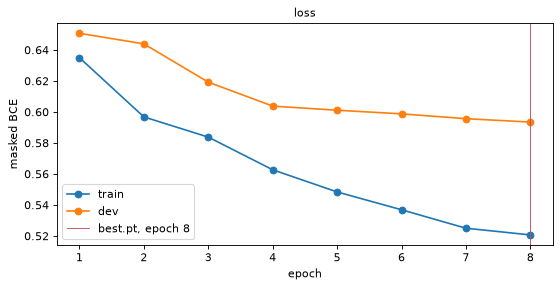

In [9]:
epochs = [h["epoch"] for h in history]
best_epoch = min(history, key=lambda h: h["dev_loss"])["epoch"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(epochs, [h["train_loss"] for h in history], "o-", label="train")
ax.plot(epochs, [h["dev_loss"] for h in history], "o-", label="dev")
ax.axvline(best_epoch, color="#c44e52", lw=0.8, label=f"best.pt, epoch {best_epoch}")
ax.set(xlabel="epoch", ylabel="masked BCE", title="loss")
ax.legend()
plt.show()

## 8. A Demo on Dev Images

This section loads `best.pt` from the run folder with `load_head`, as the eval runner does, and predicts `p_error` for a few dev images. `load_head` returns the head, the `HeadInputs` of its training, and the other fields of the checkpoint. The demo is a visual check of the maps; the scores come from the eval team.

Each row shows the camera image, the lidar AbsRel on the labeled cells, the labels, and `p_error` on every cell. The labels cover scattered cells, while the head fills the whole image.

best.pt: epoch 8, dev loss 0.5935


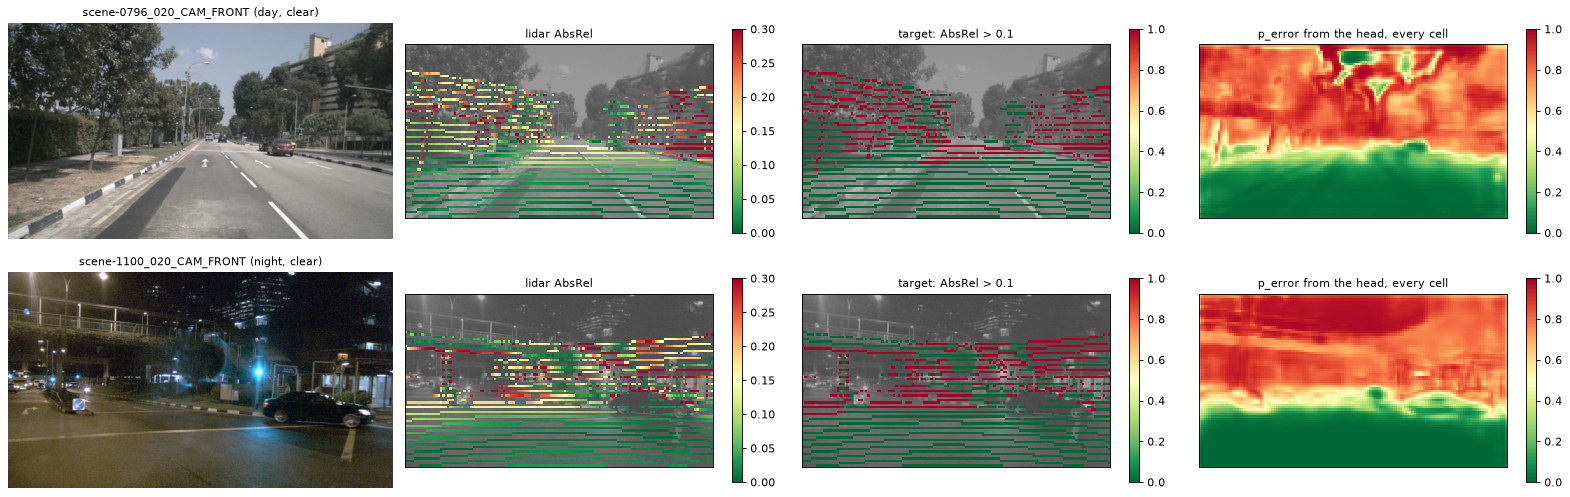

In [10]:
best, inputs, info = load_head(training.dir / "best.pt", device)
print(f"best.pt: epoch {info['epoch']}, dev loss {info['history'][-1]['dev_loss']:.4f}")

if DEMO_KEYS is None:
    groups = defaultdict(list)
    for i in training.dev_all:
        r = training.dataset.rows[i]
        groups[(r["condition"], r["weather"])].append(r)
    DEMO_KEYS = []
    for _, group in sorted(groups.items())[:3]:
        front = [r for r in group if r["channel"] == "CAM_FRONT"] or group
        DEMO_KEYS.append(front[len(front) // 2]["key"])
demo_set = ConfidenceDataset(cache, inputs)
position = {r["key"]: i for i, r in enumerate(demo_set.rows)}
tau = inputs.labels.tau

fig, axes = plt.subplots(len(DEMO_KEYS), 4, figsize=(20, 3.3 * len(DEMO_KEYS)), squeeze=False)
for row_axes, key in zip(axes, DEMO_KEYS):
    item = demo_set[position[key]]
    entry = cache.entry(key)
    rgb = entry.image()
    size = (entry.meta["image"]["width"], entry.meta["image"]["height"])
    with torch.no_grad():
        p_error = torch.sigmoid(best(item["x"][None].to(device)))[0, 0].cpu().numpy()
    labeled = item["mask"][0].numpy() > 0
    row_axes[0].imshow(rgb)
    row_axes[0].set_axis_off()
    row_axes[0].set_title(f"{key} ({entry.meta['condition']}, {entry.meta['weather']})")
    panels = [
        (item["abs_rel"][0].numpy(), labeled, dict(cmap="RdYlGn_r", vmin=0, vmax=3 * tau), "lidar AbsRel"),
        (item["target"][0].numpy(), labeled, dict(cmap="RdYlGn_r", vmin=0, vmax=1), f"target: AbsRel > {tau}"),
        (p_error, None, dict(cmap="RdYlGn_r", vmin=0, vmax=1), "p_error from the head, every cell"),
    ]
    for ax, (values, mask, kw, title) in zip(row_axes[1:], panels):
        im = draw_map(ax, values, size, image=rgb if mask is not None else None, mask=mask, **kw)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()

## 9. What the Run Writes

| File in the run folder | What it holds |
|---|---|
| `config.json` | every setting, the dev scenes, the class weight, the cache fingerprint, the git commit |
| `best.pt` | the head of the epoch with the lowest dev loss |
| `last.pt` | the head of the last epoch, with the optimizer and the schedule, to continue the run |
| `history.json` | the train and dev loss of each epoch |

`save_head` writes both checkpoints in one format, and `load_head` reads it back. A checkpoint holds the head with its input statistics, the `HeadInputs` of the training, and the names of the channels of `x`. It also records the epoch, the loss history, the class weight, the cache, and the git commit. Its fields are only tensors and plain Python values, so `torch.load` reads it with its default `weights_only=True`.

## Where to Go Next

- **Evaluation.** [`eval-template.ipynb`](eval-template.ipynb) loads a checkpoint, rebuilds its inputs from a cache, and predicts `p_error` for val images. The eval runner starts from there.
- **Ablations.** Set `cfg.inputs` in section 1 to drop a channel group, for example `HeadInputs(radar=False)` or `HeadInputs(features=False, temporal=False)`, and give the run its own `cfg.output.name`. The labels stay the same, so the eval team can compare the runs directly.
- **Labels.** `cfg.inputs = HeadInputs(labels=LabelConfig(tau=0.2))` trains on another threshold, and `LabelConfig(align="radar")` makes the labels with the radar fit instead of the lidar fit. Neither needs a new cache.
- **CARC.** [`guides/notebook-on-carc.md`](../guides/notebook-on-carc.md) opens this notebook in JupyterLab on a CARC GPU. For a long run, [`guides/training-on-carc.md`](../guides/training-on-carc.md) runs the same training as a batch job, with no session to keep open.
- **The code.** [`src/confhead/train.py`](../src/confhead/train.py) holds the settings and the training run, and [`src/confhead/head.py`](../src/confhead/head.py) holds the head, the loss, `save_head`, and `load_head`.